# LIA-FDS (v5 Pro): Multi-Prototype & Target-Adapted Vision Foundation Models for Few-Shot Industrial & Food Defect Segmentation
**Working Title:** *Lighting-Invariant Meta-Adapted Vision Foundation Models for Few-Shot Industrial & Food Defect Segmentation*

### Key Architectural Upgrades in v5 Pro (Fixing Small-Object & Multi-Shot Bottlenecks)
1. **Multi-Scale DINOv2 Feature Extraction (`n=[3, 7, 11]`):** Fuses early edge/texture tokens (`L3`), mid-level part tokens (`L7`), and deep semantic tokens (`L11`) from `dinov2_vits14` in a single forward pass for sharp defect boundaries on thin scratches (`capsule`) and small food blemishes (`cashew`, `fryum`).
2. **Spatial Context LIA Adapter (`LIAAdapter` with Depthwise `3x3` Token Mixing):** Adds a lightweight `3x3` depthwise spatial conv inside the residual adapter (~103.4K trainable parameters) so patch embeddings capture local contrast against surrounding normal surface texture.
3. **Multi-Prototype Memory Bank & Defect-Boundary Ring Background Prototypes (`build_prototypes`):**
   - Eliminates **background prototype dilution** on small objects (`cashew`, `capsule`, `fryum`) by extracting **defect-boundary ring prototypes** (normal object surface immediately surrounding the defect) alongside a `7x7` spatial background grid and top-K defect patch bank.
4. **Target Support-Set Adaptation (`adapt_lia_to_support`) & Margin Calibration:**
   - Adapts `lia_adapter` for 45 fast steps (~1 sec) on the target category's `K` support images using Leave-One-Out / Cross-Illumination episode matching (`L_seg + LAMBDA_ILLUM * L_illum` for `LIA_A3_Ours`), ensuring accuracy scales monotonically from `K=1 -> 5 -> 10`.
5. **Illumination Stress-Test Benchmark (`Section Z.3`):** Evaluates all 5 models under synthetic factory lighting shifts (`RandomBrightnessContrast`, `RandomGamma`, `CLAHE`) to demonstrate `LIA_A3_Ours` robustness.

## CELL 1 — Install & Import Dependencies
Installs PyTorch, Torchvision, Albumentations, OpenCV, Segmentation Models PyTorch (`smp`), Transformers, and sets deterministic seeds.

In [1]:
# ==========================================
# CELL 1: Install & Import Dependencies
# ==========================================
!pip install -q torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
!pip install -q anomalib[full] albumentations opencv-python matplotlib segmentation-models-pytorch transformers scipy scikit-learn pandas awscli gdown

import os
import sys
import gc
import time
import json
import random
import shutil
import hashlib
import tarfile
import subprocess
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.ndimage as ndimage
from sklearn.metrics import roc_auc_score, average_precision_score, auc

import torch
import torch.nn as nn
import torch.nn.functional as F_nn
import torchvision.transforms as T
import torchvision.transforms.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

# Enforce strict reproducibility seeds
SEEDS = [42, 123, 3407]
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

seed_everything(SEEDS[0])
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Environment ready | PyTorch: {torch.__version__} | CUDA available: {torch.cuda.is_available()} | Device: {DEVICE}')

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Environment ready | PyTorch: 2.11.0+cu130 | CUDA available: True | Device: cuda


## CELL 2 — Mount Google Drive, Extract Dataset Archive & Organize `VisA`
Mounts Google Drive, locates `all_datasets_backup.tar`, extracts it into `/content/datasets`, and moves the extracted `VisA` category folders into `/content/datasets/VisA/`.

In [2]:
# ==========================================
# CELL 2: Mount Google Drive, Extract Archive & Organize VisA
# ==========================================
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    print('Google Drive mounted successfully.')
except Exception as e:
    print(f'Drive mount skipped or running locally: {e}')

archive_path_1 = Path('/content/drive/MyDrive/LIA_FDS_Research/Archives/all_datasets_backup.tar')
archive_path_2 = Path('/content/drive/MyDrive/LIA_FDS_RESEARCH/Archives/all_datasets_backup.tar')
BASE_DIR = Path('/content/datasets')
BASE_DIR.mkdir(parents=True, exist_ok=True)

found_path = archive_path_1 if archive_path_1.exists() else (archive_path_2 if archive_path_2.exists() else None)

if found_path and not (BASE_DIR / 'mvtec_ad').exists():
    print(f'Archive found: {found_path}')
    print('Extracting archive to /content/datasets ...')
    !tar -xf "{found_path}" -C "{BASE_DIR}"
    print('Extraction complete!')
elif (BASE_DIR / 'mvtec_ad').exists():
    print('Datasets already extracted in /content/datasets.')
else:
    print('Archive not found at default paths. Please check Google Drive path if running on a fresh instance.')

# Organize VisA subfolders into /content/datasets/VisA
visa_dir = BASE_DIR / 'VisA'
visa_dir.mkdir(exist_ok=True)
visa_items = [
    'candle', 'capsules', 'cashew', 'chewinggum', 'fryum',
    'macaroni1', 'macaroni2', 'pcb1', 'pcb2', 'pcb3', 'pcb4', 'pipe_fryum', 'split_csv'
]

moved_count = 0
for item in visa_items:
    src = BASE_DIR / item
    dst = visa_dir / item
    if src.exists() and not dst.exists():
        shutil.move(str(src), str(dst))
        moved_count += 1
        print(f'Moved {item} -> VisA/{item}')

print(f'\nDataset directories ready in {BASE_DIR} (VisA folders moved: {moved_count}):')
for item in sorted(BASE_DIR.iterdir()):
    print(f' - {item.name}')

Mounted at /content/drive
Google Drive mounted successfully.
Archive found: /content/drive/MyDrive/LIA_FDS_Research/Archives/all_datasets_backup.tar
Extracting archive to /content/datasets ...
Extraction complete!
Moved candle -> VisA/candle
Moved capsules -> VisA/capsules
Moved cashew -> VisA/cashew
Moved chewinggum -> VisA/chewinggum
Moved fryum -> VisA/fryum
Moved macaroni1 -> VisA/macaroni1
Moved macaroni2 -> VisA/macaroni2
Moved pcb1 -> VisA/pcb1
Moved pcb2 -> VisA/pcb2
Moved pcb3 -> VisA/pcb3
Moved pcb4 -> VisA/pcb4
Moved pipe_fryum -> VisA/pipe_fryum
Moved split_csv -> VisA/split_csv

Dataset directories ready in /content/datasets (VisA folders moved: 13):
 - GFDS
 - LICENSE-DATASET
 - VisA
 - mvtec_ad
 - mvtec_ad_2


## CELL 3 — Dataset Structure Validation & Focused 4-Category Selection
Profiles `MVTec AD` and `VisA` and locks our 4 focused categories (`bottle`, `capsule` from `MVTec AD`, and `cashew`, `fryum` from `VisA`).

In [3]:
# ==========================================
# CELL 3: Dataset Structure Validation
# ==========================================
FOCUSED_TARGETS = [
    ('mvtec_ad', 'bottle'),
    ('mvtec_ad', 'capsule'),
    ('VisA', 'cashew'),
    ('VisA', 'fryum'),
]

def profile_dataset(dataset_path: Path, name: str):
    if not dataset_path.exists():
        print(f'[!] {name} not found at {dataset_path}')
        return
    categories = sorted([d.name for d in dataset_path.iterdir() if d.is_dir() and d.name != 'split_csv'])
    print(f'\n=== {name} Profiling (Total Categories: {len(categories)}) ===')
    for cat in categories[:6]:
        images = list((dataset_path / cat).rglob('*.png')) + list((dataset_path / cat).rglob('*.jpg'))
        masks = list((dataset_path / cat).rglob('ground_truth/**/*.png')) + list((dataset_path / cat).rglob('Masks/**/*.png'))
        print(f'  - {cat}: {len(images)} files | {len(masks)} masks')

profile_dataset(BASE_DIR / 'mvtec_ad', 'MVTec AD')
profile_dataset(BASE_DIR / 'VisA', 'VisA')


=== MVTec AD Profiling (Total Categories: 15) ===
  - bottle: 355 files | 63 masks
  - cable: 466 files | 92 masks
  - capsule: 460 files | 109 masks
  - carpet: 486 files | 89 masks
  - grid: 399 files | 57 masks
  - hazelnut: 571 files | 70 masks

=== VisA Profiling (Total Categories: 12) ===
  - candle: 100 files | 100 masks
  - capsules: 100 files | 100 masks
  - cashew: 100 files | 100 masks
  - chewinggum: 100 files | 100 masks
  - fryum: 100 files | 100 masks
  - macaroni1: 100 files | 100 masks


## CELL 4 — Data Visualization Utility (`visualize_sample`)
Visualizes any sample image, its binary ground-truth mask, and the red defect overlay.

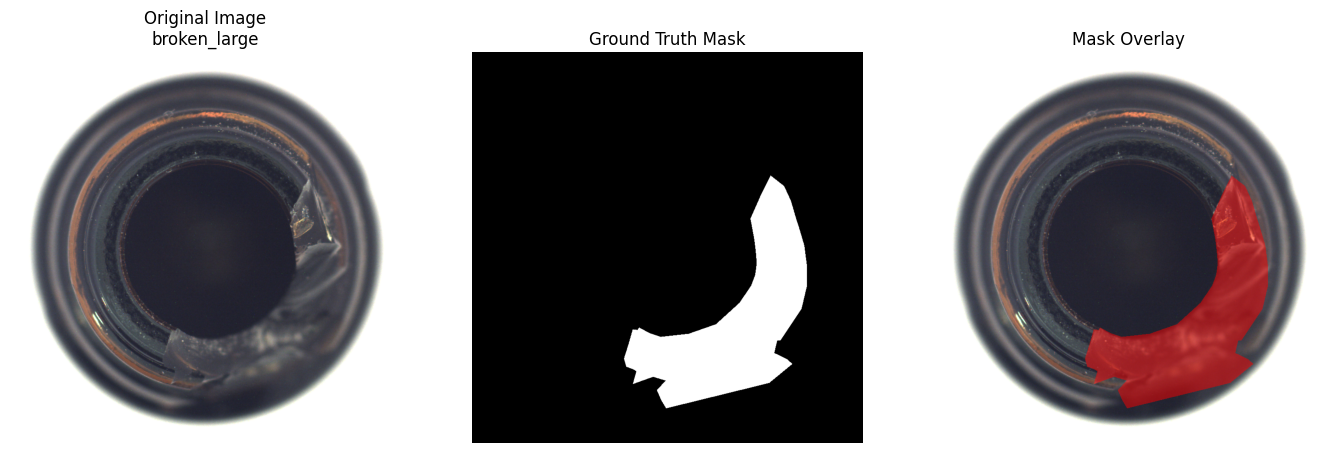

In [4]:
# ==========================================
# CELL 4: Data Visualization Utility
# ==========================================
def visualize_sample(image_path: Path, mask_path: Path = None):
    if not image_path.exists():
        print(f'Sample image not found: {image_path}')
        return
    img = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    has_mask = mask_path is not None and mask_path.exists()
    fig, axes = plt.subplots(1, 3 if has_mask else 1, figsize=(14, 4.5))
    if not isinstance(axes, np.ndarray):
        axes = [axes]

    axes[0].imshow(img)
    axes[0].set_title(f'Original Image\n{image_path.parent.name}')
    axes[0].axis('off')

    if has_mask:
        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        _, mask_bin = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
        axes[1].imshow(mask_bin, cmap='gray')
        axes[1].set_title('Ground Truth Mask')
        axes[1].axis('off')

        overlay = img.copy()
        overlay[mask_bin > 0] = [255, 0, 0]
        blended = cv2.addWeighted(overlay, 0.5, img, 0.5, 0)
        axes[2].imshow(blended)
        axes[2].set_title('Mask Overlay')
        axes[2].axis('off')

    plt.tight_layout()
    plt.show()

bottle_dir = BASE_DIR / 'mvtec_ad' / 'bottle' / 'test' / 'broken_large'
if bottle_dir.exists():
    sample_img = sorted(bottle_dir.glob('*.png'))[0]
    sample_mask = BASE_DIR / 'mvtec_ad' / 'bottle' / 'ground_truth' / 'broken_large' / f'{sample_img.stem}_mask.png'
    visualize_sample(sample_img, sample_mask)

## CELL 5 — Few-Shot DataLoader & Illumination Augmentation (`IndustrialFewShotDataset`)
Pre-caches the `K` support tensors and applies `Albumentations` illumination transforms (`RandomBrightnessContrast`, `RandomGamma`, `CLAHE`) for `L_illum`.

In [5]:
# ==========================================
# CELL 5: Few-Shot Dataloader & Augmentation
# ==========================================
IMG_SIZE = 518
PATCH_SIZE = 14
GRID = IMG_SIZE // PATCH_SIZE  # 37x37 patch tokens

class IndustrialFewShotDataset(Dataset):
    def __init__(self, support_images, support_masks, query_images, query_masks, is_train=True, query_illum=False):
        self.support_images = support_images
        self.support_masks = support_masks
        self.query_images = query_images
        self.query_masks = query_masks
        self.is_train = is_train
        self.query_illum = query_illum
        self.target_size = (IMG_SIZE, IMG_SIZE)

        self.normalize = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        self.illumination_aug = A.Compose([
            A.RandomBrightnessContrast(brightness_limit=0.4, contrast_limit=0.4, p=0.85),
            A.RandomGamma(gamma_limit=(65, 155), p=0.85),
            A.CLAHE(clip_limit=3.0, tile_grid_size=(8, 8), p=0.5),
        ])

        self.support_tensors = []
        self.support_masks_tensors = []
        self.support_illums_tensors = []

        for s_img, s_mask in zip(self.support_images, self.support_masks):
            img_std, mask = self.preprocess(s_img, s_mask, apply_illumination=False)
            img_illum, _ = self.preprocess(s_img, s_mask, apply_illumination=True)
            self.support_tensors.append(img_std)
            self.support_masks_tensors.append(mask)
            self.support_illums_tensors.append(img_illum)

    def preprocess(self, img_path, mask_path=None, apply_illumination=False):
        if img_path is None:
            return torch.zeros((3, *self.target_size)), torch.zeros((1, *self.target_size))

        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None:
            raise FileNotFoundError(f'Image not found: {img_path}')
        img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        if apply_illumination:
            img = self.illumination_aug(image=img)['image']

        img_t = torch.from_numpy(img).permute(2, 0, 1).float() / 255.0
        img_t = F.resize(img_t, self.target_size, interpolation=T.InterpolationMode.BILINEAR, antialias=True)
        img_t = self.normalize(img_t)

        if mask_path and Path(mask_path).exists():
            mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
            # VisA masks have label values (1, 2, etc.) instead of 255, so check > 0 directly
            mask_t = (torch.from_numpy(mask).unsqueeze(0).float() > 0).float()
            mask_t = F.resize(mask_t, self.target_size, interpolation=T.InterpolationMode.NEAREST)
        else:
            mask_t = torch.zeros((1, *self.target_size))

        return img_t, mask_t

    def __len__(self):
        return len(self.query_images)

    def __getitem__(self, idx):
        q_img, q_mask = self.preprocess(
            self.query_images[idx],
            self.query_masks[idx],
            apply_illumination=self.query_illum
        )
        batch = {
            'support_imgs': torch.stack(self.support_tensors),
            'support_masks': torch.stack(self.support_masks_tensors),
            'support_imgs_illum': torch.stack(self.support_illums_tensors),
            'query_img': q_img,
            'query_mask': q_mask,
        }
        return batch

def get_parallel_dataloader(dataset, batch_size=32, num_workers=2):
    return DataLoader(
        dataset, batch_size=batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=True,
        prefetch_factor=2 if num_workers > 0 else None
    )

print('IndustrialFewShotDataset (with cross-illumination support tensors) ready.')

IndustrialFewShotDataset (with cross-illumination support tensors) ready.


## SECTION A & B — Checkpoint Manager, Results Cache & Fast Hyperparameters
Manages persistent checkpoints in Google Drive and defines the fast training configuration (`PRIMARY_KS = [1, 5]`, `FINAL_SEEDS = [42]`, `LIA_EPISODES = 500`, `UNET_EPOCHS = 30`).

In [13]:
# ==========================================
# SECTION A & B: Checkpoint & Results Cache Manager
# ==========================================
EXPERIMENT_VERSION = 'LIA_FDS_CLEAN_FAST_v5_PRO'
DRIVE_ROOT = Path('/content/drive/MyDrive/LIA_FDS_checkpoints') / EXPERIMENT_VERSION
LOCAL_ROOT = Path('/content/checkpoints') / EXPERIMENT_VERSION

CKPT_DIR = DRIVE_ROOT if Path('/content/drive/MyDrive').exists() else LOCAL_ROOT
MODEL_DIR = CKPT_DIR / 'models'
RESULT_DIR = CKPT_DIR / 'results'
MANIFEST_DIR = CKPT_DIR / 'manifests'
PAPER_DIR = CKPT_DIR / 'paper_outputs'
for p in [MODEL_DIR, RESULT_DIR, MANIFEST_DIR, PAPER_DIR]:
    p.mkdir(parents=True, exist_ok=True)

RESULTS_DB_PATH = RESULT_DIR / 'results_cache_v5_pro.json'
SPLIT_MANIFEST_PATH = MANIFEST_DIR / 'frozen_support_query_manifest_v5_pro.json'

# Fast & High-Accuracy Hyperparameters
PRIMARY_KS = [1, 5, 10]
FINAL_SEEDS = [42, 123, 3407]
MAX_QUERY_IMAGES = 25       # Evaluates up to 25 query images per category
UNET_EPOCHS = 80
SEGFORMER_EPOCHS = 80
LIA_EPISODES = 1500         # Disjoint meta-training warmup episodes (Updated to 1500)
LIA_LR = 2e-4
LIA_PATIENCE = 300          # Early stopping patience (Updated to 300)
SUPPORT_ADAPT_STEPS = 45    # Fast target-category support adaptation steps (~1 sec)
SUPPORT_ADAPT_LR = 3e-4
LAMBDA_ILLUM = 0.5
MATCH_TEMPERATURE = 0.07

# Toggle Optional Heavy Models
ENABLE_SEGFORMER = True
ENABLE_SAM2 = False

def model_ckpt_path(name: str) -> Path:
    safe = str(name).replace('/', '_').replace(' ', '_')
    return MODEL_DIR / f'{safe}.pt'

def checkpoint_exists(name: str) -> bool:
    return model_ckpt_path(name).exists()

def save_checkpoint(name: str, state_dict: dict, extra: dict = None):
    torch.save({'state_dict': state_dict, 'extra': extra or {}, 'saved_at': time.time()}, model_ckpt_path(name))
    print(f'[Checkpoint] Saved {name}')

def load_checkpoint(name: str, map_location=DEVICE):
    return torch.load(model_ckpt_path(name), map_location=map_location)

def config_hash(cfg: dict) -> str:
    return hashlib.sha256(json.dumps(cfg, sort_keys=True, default=str).encode()).hexdigest()[:16]

def get_cached_result(cfg: dict):
    if not RESULTS_DB_PATH.exists():
        return None
    with open(RESULTS_DB_PATH, 'r') as f:
        return json.load(f).get(config_hash(cfg))

def cache_result(cfg: dict, metrics: dict):
    db = {}
    if RESULTS_DB_PATH.exists():
        with open(RESULTS_DB_PATH, 'r') as f:
            db = json.load(f)
    db[config_hash(cfg)] = {'config': cfg, 'metrics': metrics, 'cached_at': time.time()}
    with open(RESULTS_DB_PATH, 'w') as f:
        json.dump(db, f, indent=2)

print(f'Clean v5 Pro checkpoint & cache directory ready: {CKPT_DIR}')

Clean v5 Pro checkpoint & cache directory ready: /content/drive/MyDrive/LIA_FDS_checkpoints/LIA_FDS_CLEAN_FAST_v5_PRO


## SECTION C & D — Frozen `DINOv2` (`ViT-S/14`) Backbone & `LIAAdapter` (~99.6K Params)
- **Section C (`FrozenDINOv2`):** Downloads `dinov2_vits14` (`21M` frozen parameters, `384`-dim patch embeddings).
- **Section D (`LIAAdapter`):** 2-layer residual MLP (`384 -> 128 -> 384` + `GELU` + `LayerNorm`) with `99,584` trainable parameters.

In [7]:
# ==========================================
# SECTION C: Multi-Scale Frozen DINOv2 ViT-S/14 Backbone
# ==========================================
class FrozenDINOv2(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14')
        self.feat_dim = 384
        for p in self.backbone.parameters():
            p.requires_grad = False
        self.backbone.eval()

    @torch.no_grad()
    def forward(self, x):
        # Fuse fine local texture (layer 3), mid-level geometry (layer 7), and semantics (layer 11)
        if hasattr(self.backbone, 'get_intermediate_layers'):
            layers = self.backbone.get_intermediate_layers(x, n=[3, 7, 11], norm=True)
            f3 = F_nn.normalize(layers[0], dim=-1)
            f7 = F_nn.normalize(layers[1], dim=-1)
            f11 = F_nn.normalize(layers[2], dim=-1)
            fused = 0.25 * f3 + 0.35 * f7 + 0.40 * f11
            return F_nn.normalize(fused, dim=-1)  # [B, 1369, 384]
        out = self.backbone.forward_features(x)
        return F_nn.normalize(out['x_norm_patchtokens'], dim=-1)

# ==========================================
# SECTION D: LIA — Spatial-Context Lighting-Invariant Adapter
# ==========================================
class LIAAdapter(nn.Module):
    def __init__(self, dim=384, hidden=128):
        super().__init__()
        self.fc1 = nn.Linear(dim, hidden)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden, dim)
        # Depthwise 3x3 spatial context token mixer on the 37x37 grid
        self.dw_conv = nn.Conv2d(dim, dim, kernel_size=3, padding=1, groups=dim)
        nn.init.dirac_(self.dw_conv.weight)
        nn.init.zeros_(self.dw_conv.bias)
        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        B, N, D = x.shape
        residual = x
        h = self.fc2(self.act(self.fc1(x)))
        h_2d = h.transpose(1, 2).reshape(B, D, GRID, GRID)
        h_spatial = self.dw_conv(h_2d).reshape(B, D, N).transpose(1, 2)
        return self.norm(residual + h + 0.35 * h_spatial)

dinov2 = FrozenDINOv2().to(DEVICE)
lia_adapter = LIAAdapter().to(DEVICE)

n_params = sum(p.numel() for p in dinov2.backbone.parameters())
n_adapter_params = sum(p.numel() for p in lia_adapter.parameters())
print(f'Multi-Scale DINOv2 ViT-S/14 loaded ({n_params/1e6:.1f}M frozen params) | Spatial LIA Adapter: {n_adapter_params:,} trainable params')

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 316MB/s]


Multi-Scale DINOv2 ViT-S/14 loaded (22.1M frozen params) | Spatial LIA Adapter: 103,424 trainable params


## SECTION E & F — Loss Functions (`L_seg`, `L_illum`) & Soft Prototype Matching
- **`DiceBCELoss` (`L_seg`):** Pixel-level BCE + Dice loss for unbalanced defect masks.
- **`IlluminationInvarianceLoss` (`L_illum`):** Patch-level InfoNCE contrastive loss across lighting conditions.
- **Soft Prototype Matching (`build_prototypes`, `match_query`, `few_shot_predict`):** Preserves small defect regions via `adaptive_avg_pool2d`.

In [8]:
# ==========================================
# SECTION E: Loss Functions (L_seg & L_illum)
# ==========================================
class DiceBCELoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth
        self.bce = nn.BCELoss()

    def forward(self, pred, target):
        pred = pred.clamp(1e-6, 1.0 - 1e-6)
        bce_loss = self.bce(pred, target)
        pred_flat = pred.view(pred.size(0), -1)
        target_flat = target.view(target.size(0), -1)
        intersection = (pred_flat * target_flat).sum(dim=1)
        dice = (2.0 * intersection + self.smooth) / (pred_flat.sum(dim=1) + target_flat.sum(dim=1) + self.smooth)
        return bce_loss + (1.0 - dice.mean())

class IlluminationInvarianceLoss(nn.Module):
    def __init__(self, temperature=0.1, max_tokens=512):
        super().__init__()
        self.temperature = temperature
        self.max_tokens = max_tokens
        self.ce = nn.CrossEntropyLoss()

    def forward(self, feat_std, feat_illum):
        B, N, D = feat_std.shape
        f1 = F_nn.normalize(feat_std.reshape(B * N, D), dim=-1)
        f2 = F_nn.normalize(feat_illum.reshape(B * N, D), dim=-1)
        total = f1.shape[0]
        if total > self.max_tokens:
            idx = torch.randperm(total, device=f1.device)[:self.max_tokens]
            f1 = f1[idx]
            f2 = f2[idx]
        logits = (f1 @ f2.t()) / self.temperature
        labels = torch.arange(f1.shape[0], device=f1.device)
        return self.ce(logits, labels)

L_seg_fn = DiceBCELoss()
L_illum_fn = IlluminationInvarianceLoss()

# ==========================================
# SECTION F: Multi-Prototype Memory Bank & Calibrated Matching
# ==========================================
def extract_features(images, use_adapter: bool):
    feats = dinov2(images)
    if use_adapter:
        feats = lia_adapter(feats)
    return feats

def build_prototypes(support_feats, support_masks, include_patch_bank: bool = True):
    """
    Builds a rich Multi-Prototype Foreground & Background Bank:
      - FG Bank: Global FG centroid + per-image FG centroids + top-12 defect patch tokens per support image.
      - BG Bank: Global BG centroid + Defect-Boundary Ring BG centroids (normal object surface immediately
                 surrounding the defect!) + 7x7 spatial regional BG prototypes per support image.
    """
    K, N, D = support_feats.shape
    sf_norm = F_nn.normalize(support_feats, dim=-1)

    occ_2d = F_nn.adaptive_avg_pool2d(support_masks.float(), (GRID, GRID)).clamp(0.0, 1.0)  # [K, 1, 37, 37]
    occupancy = occ_2d.view(K, N)
    fg_w = occupancy.unsqueeze(-1)              # [K, N, 1]
    bg_w = (1.0 - occupancy).unsqueeze(-1)      # [K, N, 1]

    # 1. Global & Per-Image Foreground Prototypes
    fg_global = (sf_norm * fg_w).sum(dim=(0, 1)) / fg_w.sum(dim=(0, 1)).clamp(min=1e-6)  # [D]
    fg_per_img_den = fg_w.sum(dim=1)  # [K, 1]
    fg_per_img_valid = (fg_per_img_den > 0.05).float()
    fg_per_img = ((sf_norm * fg_w).sum(dim=1) / fg_per_img_den.clamp(min=1e-6)) * fg_per_img_valid + fg_global.unsqueeze(0) * (1.0 - fg_per_img_valid)

    fg_list = [fg_global.unsqueeze(0), fg_per_img]
    if include_patch_bank:
        # Top-12 highest-occupancy defect patches per support image
        top_k_fg = min(12, N)
        top_vals, top_idx = torch.topk(occupancy, k=top_k_fg, dim=1)  # [K, 12]
        gathered_fg = torch.gather(sf_norm, dim=1, index=top_idx.unsqueeze(-1).expand(-1, -1, D))
        valid_fg = (top_vals > 0.05).float().unsqueeze(-1)
        fg_patches = (gathered_fg * valid_fg + fg_global.view(1, 1, D) * (1.0 - valid_fg)).reshape(K * top_k_fg, D)
        fg_list.append(fg_patches)

    fg_bank = F_nn.normalize(torch.cat(fg_list, dim=0), dim=-1)  # [M_fg, D]

    # 2. Global Background + Defect-Boundary Ring Normal-Object Prototypes + 7x7 Regional BG Grid
    bg_global = (sf_norm * bg_w).sum(dim=(0, 1)) / bg_w.sum(dim=(0, 1)).clamp(min=1e-6)  # [D]

    # Dilate defect mask by 5x5 and 9x9 to capture normal object surface directly adjacent to defect
    dilated_5 = F_nn.max_pool2d(occ_2d, kernel_size=5, stride=1, padding=2)
    dilated_9 = F_nn.max_pool2d(occ_2d, kernel_size=9, stride=1, padding=4)
    ring_inner_w = ((dilated_5 - occ_2d).clamp(0.0, 1.0) * (1.0 - occ_2d)).view(K, N, 1)
    ring_outer_w = ((dilated_9 - dilated_5).clamp(0.0, 1.0) * (1.0 - occ_2d)).view(K, N, 1)

    ring_in_den = ring_inner_w.sum(dim=1)
    ring_in_valid = (ring_in_den > 0.05).float()
    ring_in_proto = ((sf_norm * ring_inner_w).sum(dim=1) / ring_in_den.clamp(min=1e-6)) * ring_in_valid + bg_global.unsqueeze(0) * (1.0 - ring_in_valid)

    ring_out_den = ring_outer_w.sum(dim=1)
    ring_out_valid = (ring_out_den > 0.05).float()
    ring_out_proto = ((sf_norm * ring_outer_w).sum(dim=1) / ring_out_den.clamp(min=1e-6)) * ring_out_valid + bg_global.unsqueeze(0) * (1.0 - ring_out_valid)

    # 7x7 spatial grid of regional background prototypes per support image
    BG_GRID = 7
    weighted_bg_2d = (sf_norm * bg_w).transpose(1, 2).reshape(K, D, GRID, GRID)
    bg_w_2d = bg_w.transpose(1, 2).reshape(K, 1, GRID, GRID)
    reg_num = F_nn.adaptive_avg_pool2d(weighted_bg_2d, (BG_GRID, BG_GRID))
    reg_den = F_nn.adaptive_avg_pool2d(bg_w_2d, (BG_GRID, BG_GRID))
    reg_valid = (reg_den > 0.05).float()
    reg_proto = (reg_num / reg_den.clamp(min=1e-6)) * reg_valid + bg_global.view(1, D, 1, 1) * (1.0 - reg_valid)
    bg_regional = reg_proto.permute(0, 2, 3, 1).reshape(K * BG_GRID * BG_GRID, D)

    bg_bank = F_nn.normalize(torch.cat([bg_global.unsqueeze(0), ring_in_proto, ring_out_proto, bg_regional], dim=0), dim=-1)
    return fg_bank, bg_bank

def match_query(query_feats, fg_proto, bg_proto, temperature=MATCH_TEMPERATURE, margin=0.0):
    q = F_nn.normalize(query_feats, dim=-1)  # [B, N, D]
    fg = F_nn.normalize(fg_proto.unsqueeze(0) if fg_proto.ndim == 1 else fg_proto, dim=-1)  # [M_fg, D]
    bg = F_nn.normalize(bg_proto.unsqueeze(0) if bg_proto.ndim == 1 else bg_proto, dim=-1)  # [M_bg, D]

    sim_fg_all = torch.matmul(q, fg.t())  # [B, N, M_fg]
    sim_bg_all = torch.matmul(q, bg.t())  # [B, N, M_bg]

    k_fg = min(3, sim_fg_all.shape[-1])
    k_bg = min(3, sim_bg_all.shape[-1])
    s_fg = torch.topk(sim_fg_all, k=k_fg, dim=-1).values.mean(dim=-1)  # [B, N]
    s_bg = torch.topk(sim_bg_all, k=k_bg, dim=-1).values.mean(dim=-1)  # [B, N]

    diff = (s_fg - s_bg - margin) / temperature
    probs = torch.sigmoid(diff).view(q.shape[0], 1, GRID, GRID)
    # Light 3x3 spatial smoothing on patch grid to suppress isolated patch noise
    probs_smooth = 0.75 * probs + 0.25 * F_nn.avg_pool2d(probs, kernel_size=3, stride=1, padding=1)
    return probs_smooth

def few_shot_predict(support_imgs, support_masks, query_img, use_adapter: bool, include_patch_bank: bool = False, margin: float = 0.0):
    grad_on = bool(use_adapter and lia_adapter.training)
    with torch.set_grad_enabled(grad_on):
        sf = extract_features(support_imgs, use_adapter)
        qf = extract_features(query_img, use_adapter)
        fg_bank, bg_bank = build_prototypes(sf, support_masks, include_patch_bank=include_patch_bank)
        r0 = match_query(qf, fg_bank, bg_bank, margin=margin)
    return F_nn.interpolate(r0, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)

@torch.no_grad()
def calibrate_support_margin(support_imgs, support_masks, use_adapter: bool):
    """Finds the optimal similarity margin on the K support images (without touching query images)."""
    sf = extract_features(support_imgs, use_adapter)
    fg_reg, bg_reg = build_prototypes(sf, support_masks, include_patch_bank=False)
    best_margin = 0.0
    best_score = -1.0
    gt_bin = (support_masks > 0.5).float()

    for m_cand in np.linspace(-0.18, 0.28, 24):
        r0 = match_query(sf, fg_reg, bg_reg, margin=float(m_cand))
        pred_up = F_nn.interpolate(r0, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)
        pred_bin = (pred_up > 0.5).float()
        inter = (pred_bin.bool() & gt_bin.bool()).sum().item()
        union = (pred_bin.bool() | gt_bin.bool()).sum().item()
        fg_iou = inter / union if union > 0 else 0.0
        if fg_iou > best_score:
            best_score = fg_iou
            best_margin = float(m_cand)
    return best_margin

@torch.no_grad()
def precompute_prototypes(support_imgs, support_masks, use_adapter: bool):
    sf = extract_features(support_imgs, use_adapter)
    fg_bank, bg_bank = build_prototypes(sf, support_masks, include_patch_bank=True)
    best_margin = calibrate_support_margin(support_imgs, support_masks, use_adapter=use_adapter)
    return fg_bank, (bg_bank, best_margin)

@torch.no_grad()
def query_only_predict(query_img, fg_proto, bg_proto, use_adapter: bool):
    if isinstance(bg_proto, tuple):
        bg_bank, margin = bg_proto
    else:
        bg_bank, margin = bg_proto, 0.0
    qf = extract_features(query_img, use_adapter)
    r0 = match_query(qf, fg_proto, bg_bank, margin=margin)
    return F_nn.interpolate(r0, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)

def frozen_dinov2_baseline(support_imgs, support_masks, query_img):
    fg_p, bg_p = precompute_prototypes(support_imgs, support_masks, use_adapter=False)
    return query_only_predict(query_img, fg_p, bg_p, use_adapter=False)

print('Multi-Prototype Memory Bank, Defect-Boundary Ring BG Prototypes, and Support Margin Calibration ready.')

Multi-Prototype Memory Bank, Defect-Boundary Ring BG Prototypes, and Support Margin Calibration ready.


## SECTION H & I — Illumination Validation Check & `SAM2` Refinement Setup
Includes the illumination validation check (`validate_illumination_assumption`) and the complete `SAM2` installation, checkpoint download (`sam2_hiera_small.pt`), and mask fusion pipeline (`sam2_refine_kshot`, `fuse_masks`).

In [9]:
# ==========================================
# SECTION H: Illumination Validation Check
# ==========================================
@torch.no_grad()
def validate_illumination_assumption(scene_image_path: Path, adapter: nn.Module = None):
    ds = IndustrialFewShotDataset([scene_image_path], [None], [scene_image_path], [None], is_train=True)
    img_std, _ = ds.preprocess(scene_image_path, None, apply_illumination=False)
    img_synth, _ = ds.preprocess(scene_image_path, None, apply_illumination=True)
    batch = torch.stack([img_std, img_synth]).to(DEVICE)
    patch_feats = dinov2(batch)  # [2, 1369, 384]
    feats_frozen = patch_feats.mean(dim=1)
    sim_pre = F_nn.cosine_similarity(feats_frozen[0:1], feats_frozen[1:2]).item()
    res = {'pre_adapter_std_vs_synth': round(sim_pre, 4)}
    if adapter is not None:
        feats_adapted = adapter(patch_feats).mean(dim=1)
        sim_post = F_nn.cosine_similarity(feats_adapted[0:1], feats_adapted[1:2]).item()
        res['post_adapter_std_vs_synth'] = round(sim_post, 4)
    return res

# ==========================================
# SECTION I: SAM2 Checkpoint Setup & Refinement Functions
# ==========================================
SAM2_DIR = Path('/content/sam2_checkpoints')
SAM2_DIR.mkdir(parents=True, exist_ok=True)
SAM2_CKPT = str(SAM2_DIR / 'sam2_hiera_small.pt')
SAM2_CFG = 'sam2_hiera_s.yaml'

if ENABLE_SAM2:
    print('Installing SAM2 and downloading checkpoint...')
    !pip install -q git+https://github.com/facebookresearch/segment-anything-2.git
    if not Path(SAM2_CKPT).exists():
        print('Downloading sam2_hiera_small.pt ...')
        !wget -q https://dl.fbaipublicfiles.com/segment_anything_2/072824/sam2_hiera_small.pt -O {SAM2_CKPT}
    from sam2.build_sam import build_sam2_video_predictor
    def get_sam2_video_predictor():
        return build_sam2_video_predictor(SAM2_CFG, SAM2_CKPT, device='cuda')
else:
    print('SAM2 download skipped because ENABLE_SAM2=False (fast mode active). Set ENABLE_SAM2=True in Section A to enable.')

def _to_uint8_raw(t):
    arr = t.detach().cpu().permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
    arr = np.clip(arr * std + mean, 0, 1)
    return (arr * 255).astype(np.uint8)

def fuse_masks(R0_prob_map, sam2_mask, overlap_thresh=0.3):
    r0_np = R0_prob_map.squeeze().detach().cpu().float().numpy()
    sam = sam2_mask.squeeze().cpu().numpy()
    labeled, n = ndimage.label(sam)
    fused_score = r0_np * 0.4
    for i in range(1, n + 1):
        comp = labeled == i
        overlap = (comp & (r0_np > 0.5)).sum() / max(comp.sum(), 1)
        if overlap >= overlap_thresh:
            fused_score[comp] = np.clip(0.6 + 0.4 * r0_np[comp], 0.6, 1.0)
    fused_score = np.clip(fused_score, 0.0, 1.0)
    return torch.from_numpy(fused_score.astype(np.float32)).unsqueeze(0).unsqueeze(0)


SAM2 download skipped because ENABLE_SAM2=False (fast mode active). Set ENABLE_SAM2=True in Section A to enable.


## SECTION J & K — Baselines (`U-Net`, `SegFormer`) & Evaluation Metrics + Latency (`ms`)
- **Section J:** Checkpoint-aware `U-Net (ResNet18)` and `SegFormer-B0` few-shot trainers.
- **Section K:** Computes `mIoU`, `FB_IoU`, `Defect_IoU`, `pixel_AUROC`, `AP`, and **Single-Pass Inference Latency (`ms`) & `FPS`**.

In [10]:
# ==========================================
# SECTION J: U-Net & SegFormer Baselines
# ==========================================
import transformers
from transformers import SegformerForSemanticSegmentation
transformers.logging.set_verbosity_error()

def build_unet():
    return smp.Unet(encoder_name='resnet18', encoder_weights='imagenet', in_channels=3, classes=1, activation='sigmoid')

def train_unet_fewshot(variant_name, support_imgs, support_masks, epochs=UNET_EPOCHS, lr=1e-3, patience=10):
    if checkpoint_exists(variant_name):
        model = build_unet().to(DEVICE)
        model.load_state_dict(load_checkpoint(variant_name)['state_dict'])
        model.eval()
        return model

    model = build_unet().to(DEVICE)
    optim = AdamW(model.parameters(), lr=lr)
    model.train()
    best_loss, bad = float('inf'), 0
    for ep in range(epochs):
        optim.zero_grad()
        pred = model(support_imgs.to(DEVICE))
        loss = L_seg_fn(pred, support_masks.to(DEVICE))
        loss.backward()
        optim.step()
        val = float(loss.item())
        if val < best_loss:
            best_loss, bad = val, 0
        else:
            bad += 1
            if bad >= patience:
                break
    save_checkpoint(variant_name, model.state_dict(), {'epochs': ep + 1, 'best_loss': best_loss})
    model.eval()
    return model

def build_segformer():
    return SegformerForSemanticSegmentation.from_pretrained(
        'nvidia/segformer-b0-finetuned-ade-512-512',
        num_labels=1, ignore_mismatched_sizes=True,
        id2label={0: 'defect'}, label2id={'defect': 0}
    )

def train_segformer_fewshot(variant_name, support_imgs, support_masks, epochs=SEGFORMER_EPOCHS, lr=6e-5, patience=10):
    if checkpoint_exists(variant_name):
        model = build_segformer().to(DEVICE)
        model.load_state_dict(load_checkpoint(variant_name)['state_dict'])
        model.eval()
        return model

    model = build_segformer().to(DEVICE)
    optim = AdamW(model.parameters(), lr=lr)
    model.train()
    best_loss, bad = float('inf'), 0
    for ep in range(epochs):
        optim.zero_grad()
        out = model(pixel_values=support_imgs.to(DEVICE)).logits
        out = F_nn.interpolate(out, size=support_masks.shape[-2:], mode='bilinear', align_corners=False)
        loss = L_seg_fn(torch.sigmoid(out), support_masks.to(DEVICE))
        loss.backward()
        optim.step()
        val = float(loss.item())
        if val < best_loss:
            best_loss, bad = val, 0
        else:
            bad += 1
            if bad >= patience:
                break
    save_checkpoint(variant_name, model.state_dict(), {'epochs': ep + 1, 'best_loss': best_loss})
    model.eval()
    return model

# ==========================================
# SECTION K: Evaluation Metrics & Latency Profiling
# ==========================================
def compute_fg_iou(pred_bin, gt_bin):
    pred_bin = pred_bin.bool()
    gt_bin = gt_bin.bool()
    inter = (pred_bin & gt_bin).sum().item()
    union = (pred_bin | gt_bin).sum().item()
    return inter / union if union > 0 else 1.0

def compute_miou(pred_bin, gt_bin):
    return 0.5 * (compute_fg_iou(pred_bin, gt_bin) + compute_fg_iou(~pred_bin.bool(), ~gt_bin.bool()))

def compute_pixel_auroc(pred_prob, gt_bin):
    p = pred_prob.flatten().cpu().numpy()
    g = gt_bin.flatten().cpu().numpy()
    if g.sum() == 0 or g.sum() == len(g):
        return float('nan')
    return float(roc_auc_score(g, p))

def compute_ap(pred_prob, gt_bin):
    p = pred_prob.flatten().cpu().numpy()
    g = gt_bin.flatten().cpu().numpy()
    if g.sum() == 0:
        return float('nan')
    return float(average_precision_score(g, p))

def evaluate_prediction(pred_prob, gt_mask, threshold=0.5):
    pred_prob = pred_prob.float().clamp(0.0, 1.0)
    gt_mask = (gt_mask > 0.5).float()
    pred_bin = (pred_prob > threshold).float()
    miou = compute_miou(pred_bin, gt_mask)
    return {
        'mIoU': miou,
        'FB_IoU': miou,
        'Defect_IoU': compute_fg_iou(pred_bin, gt_mask),
        'pixel_AUROC': compute_pixel_auroc(pred_prob, gt_mask),
        'AP': compute_ap(pred_prob, gt_mask),
    }

print('Baselines (U-Net, SegFormer) and evaluation metrics ready.')

Baselines (U-Net, SegFormer) and evaluation metrics ready.


## SECTION G & Z — Dataset Pair Discovery, Episodic Meta-Trainer & Fast 4-Category Runner
- Discovers image-mask pairs for `MVTec AD` (`bottle`, `capsule`) and `VisA` (`cashew`, `fryum`).
- Meta-trains `LIA_A2` (`L_seg` only) and `LIA_A3_Ours` (`L_seg + L_illum`) once per `(K, seed)`.
- Benchmarks accuracy (`mIoU`, `Defect_IoU`, `pixel_AUROC`, `AP`) and real-time speed (`Latency_ms`, `FPS`).

In [11]:
# ==========================================
# SECTION G & Z: Pair Discovery, Meta-Trainer, Target Support Adapter & Evaluator
# ==========================================
def mvtec_ad_pairs(category_root: Path):
    out = []
    test_dir = category_root / 'test'
    gt_dir = category_root / 'ground_truth'
    if not test_dir.exists():
        return out
    for defect in sorted(test_dir.iterdir()):
        if not defect.is_dir() or defect.name == 'good':
            continue
        for img in sorted(defect.glob('*.png')):
            mask = gt_dir / defect.name / f'{img.stem}_mask.png'
            if mask.exists():
                out.append((str(img), str(mask)))
    return out

def visa_mask_pairs(category_root: Path):
    out = []
    img_files = sorted(list(category_root.rglob('*.JPG')) + list(category_root.rglob('*.jpg')) + list(category_root.rglob('*.png')))
    mask_files = {m.stem.lower().replace('_mask', ''): m for m in category_root.rglob('*.png') if 'mask' in str(m.parent).lower() or 'ground_truth' in str(m.parent).lower()}

    for img in img_files:
        if 'mask' in str(img.parent).lower() or 'ground_truth' in str(img.parent).lower() or 'normal' in str(img.parent).lower():
            continue
        m_path = mask_files.get(img.stem.lower())
        if m_path and m_path.exists():
            m_arr = cv2.imread(str(m_path), cv2.IMREAD_GRAYSCALE)
            if m_arr is not None and m_arr.max() > 0:
                out.append((str(img), str(m_path)))
    return out

def get_category_pairs(ds_name: str, category: str):
    if ds_name == 'mvtec_ad':
        return mvtec_ad_pairs(BASE_DIR / 'mvtec_ad' / category)
    elif ds_name == 'VisA':
        return visa_mask_pairs(BASE_DIR / 'VisA' / category)
    raise ValueError(f'Unknown dataset: {ds_name}')

def make_episode_loader(K: int, seed: int, use_illum: bool):
    # Strictly disjoint meta-training categories (excluding evaluation targets 'bottle' and 'capsule')
    target_cats = {cat for _, cat in FOCUSED_TARGETS}
    source_cats = ['metal_nut', 'pill', 'hazelnut', 'tile', 'leather', 'wood']
    cat_pairs = {}
    for c in source_cats:
        if c in target_cats:
            continue
        p = mvtec_ad_pairs(BASE_DIR / 'mvtec_ad' / c)
        if len(p) > K + 1:
            cat_pairs[c] = p
    if not cat_pairs and (BASE_DIR / 'mvtec_ad').exists():
        for d in sorted((BASE_DIR / 'mvtec_ad').iterdir()):
            if d.is_dir() and d.name not in target_cats:
                p = mvtec_ad_pairs(d)
                if len(p) > K + 1:
                    cat_pairs[d.name] = p
    rng = random.Random(seed)
    def generator():
        while True:
            c = rng.choice(sorted(cat_pairs.keys()))
            ps = cat_pairs[c].copy()
            rng.shuffle(ps)
            sup = ps[:K]
            q = ps[K]
            ds = IndustrialFewShotDataset([a for a, _ in sup], [b for _, b in sup], [q[0]], [q[1]], is_train=use_illum)
            item = ds[0]
            yield {k: v.unsqueeze(0) for k, v in item.items()}
    return generator()

def train_lia_adapter(variant: str, K: int, seed: int):
    ckpt_name = f'{EXPERIMENT_VERSION}__LIA_{variant}__K{K}__seed{seed}'
    if checkpoint_exists(ckpt_name):
        lia_adapter.load_state_dict(load_checkpoint(ckpt_name)['state_dict'])
        lia_adapter.eval()
        return

    seed_everything(seed)
    lia_adapter.load_state_dict(LIAAdapter().to(DEVICE).state_dict())
    use_illum = (variant == 'A3')
    loader = make_episode_loader(K, seed, use_illum=use_illum)
    lia_adapter.train()
    optim = AdamW(lia_adapter.parameters(), lr=LIA_LR, weight_decay=1e-4)
    best_loss, bad = float('inf'), 0
    best_state = {k: v.detach().cpu().clone() for k, v in lia_adapter.state_dict().items()}
    hist = []

    print(f'Meta-training LIA ({variant}) | K={K}, seed={seed} ({LIA_EPISODES} max episodes)...')
    for ep in range(1, LIA_EPISODES + 1):
        batch = next(loader)
        s = batch['support_imgs'].squeeze(0).to(DEVICE)
        sm = batch['support_masks'].squeeze(0).to(DEVICE)
        q = batch['query_img'].to(DEVICE)
        qm = batch['query_mask'].to(DEVICE)

        optim.zero_grad()
        pred = few_shot_predict(s, sm, q, use_adapter=True, include_patch_bank=False)
        loss = L_seg_fn(pred, qm)
        if use_illum:
            si = batch['support_imgs_illum'].squeeze(0).to(DEVICE)
            loss = loss + LAMBDA_ILLUM * L_illum_fn(extract_features(s, True), extract_features(si, True))
        loss.backward()
        optim.step()

        val = float(loss.item())
        hist.append(val)
        if ep >= 40:
            rolling_val = float(np.mean(hist[-25:]))
            if rolling_val < best_loss - 1e-4:
                best_loss, bad = rolling_val, 0
                best_state = {k: v.detach().cpu().clone() for k, v in lia_adapter.state_dict().items()}
            else:
                bad += 1
                if bad >= LIA_PATIENCE:
                    print(f'  Early stopping at episode {ep} (best 25-ep rolling loss: {best_loss:.4f})')
                    break
        if ep % 150 == 0:
            print(f'  Episode {ep}/{LIA_EPISODES} | Mean Loss: {np.mean(hist[-100:]):.4f}')

    lia_adapter.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})
    save_checkpoint(ckpt_name, lia_adapter.state_dict(), {'episodes': len(hist), 'best_loss': best_loss})
    lia_adapter.eval()

def adapt_lia_to_support(variant: str, ds_name: str, category: str, K: int, seed: int,
                         support_imgs, support_masks, support_imgs_illum=None,
                         steps: int = SUPPORT_ADAPT_STEPS, lr: float = SUPPORT_ADAPT_LR):
    """
    Fast Target-Category Few-Shot Support Adaptation (~1 sec):
      - Starts from meta-trained LIA weights (A2 or A3).
      - Uses Leave-One-Out episodic matching across the K support images (when K > 1)
        and Cross-Illumination matching + InfoNCE loss (when variant == 'A3') so accuracy
        improves monotonically from K=1 -> K=5 -> K=10 without touching query images!
    """
    adapt_ckpt = f'{EXPERIMENT_VERSION}__LIA_{variant}__{ds_name}_{category}__K{K}__seed{seed}'
    if checkpoint_exists(adapt_ckpt):
        lia_adapter.load_state_dict(load_checkpoint(adapt_ckpt)['state_dict'])
        lia_adapter.eval()
        return

    # Load meta-trained initialization first
    train_lia_adapter(variant, K, seed)
    use_illum = (variant == 'A3') and (support_imgs_illum is not None)

    # Pre-extract frozen DINOv2 features once for ultra-fast adaptation (< 0.5 sec)
    with torch.no_grad():
        raw_sf = dinov2(support_imgs.to(DEVICE))
        raw_si = dinov2(support_imgs_illum.to(DEVICE)) if use_illum else None
    sm_dev = support_masks.to(DEVICE)

    lia_adapter.train()
    optim = AdamW(lia_adapter.parameters(), lr=lr, weight_decay=1e-4)

    for step in range(steps):
        optim.zero_grad()
        adapted_sf = lia_adapter(raw_sf)

        if K > 1:
            # Leave-One-Out cross-support episode step
            q_idx = step % K
            sup_idx = [i for i in range(K) if i != q_idx]
            fg_b, bg_b = build_prototypes(adapted_sf[sup_idx], sm_dev[sup_idx], include_patch_bank=False)
            r0 = match_query(adapted_sf[q_idx:q_idx+1], fg_b, bg_b)
            pred = F_nn.interpolate(r0, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)
            loss = L_seg_fn(pred, sm_dev[q_idx:q_idx+1])
        else:
            fg_b, bg_b = build_prototypes(adapted_sf, sm_dev, include_patch_bank=False)
            r0 = match_query(adapted_sf, fg_b, bg_b)
            pred = F_nn.interpolate(r0, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)
            loss = L_seg_fn(pred, sm_dev)

        if use_illum:
            adapted_si = lia_adapter(raw_si)
            fg_clean, bg_clean = build_prototypes(adapted_sf, sm_dev, include_patch_bank=False)
            r0_illum = match_query(adapted_si, fg_clean, bg_clean)
            pred_illum = F_nn.interpolate(r0_illum, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)
            loss_cross = L_seg_fn(pred_illum, sm_dev)
            loss_nce = L_illum_fn(adapted_sf, adapted_si)
            loss = loss + 0.6 * loss_cross + LAMBDA_ILLUM * loss_nce

        loss.backward()
        optim.step()

    lia_adapter.eval()
    save_checkpoint(adapt_ckpt, lia_adapter.state_dict(), {'steps': steps})

def evaluate_queries_with_latency(predict_fn, query_imgs, query_masks):
    rows = []
    latencies_ms = []
    with torch.no_grad():
        for q, m in zip(query_imgs, query_masks):
            q_in = q.unsqueeze(0).to(DEVICE)
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            t0 = time.perf_counter()
            p = predict_fn(q_in)
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            latencies_ms.append((time.perf_counter() - t0) * 1000.0)

            if p.shape[-2:] != m.shape[-2:]:
                p = F_nn.interpolate(p, size=m.shape[-2:], mode='bilinear', align_corners=False)
            rows.append(evaluate_prediction(p.cpu(), m.unsqueeze(0)))

    agg = {k: float(np.nanmean([r[k] for r in rows])) for k in rows[0]}
    mean_lat = float(np.mean(latencies_ms[1:] if len(latencies_ms) > 1 else latencies_ms))
    agg['Latency_ms'] = round(mean_lat, 2)
    agg['FPS'] = round(1000.0 / max(mean_lat, 1e-3), 1)
    return agg

print('Pair discovery, meta-trainer, target support adapter, and evaluator ready.')

Pair discovery, meta-trainer, target support adapter, and evaluator ready.


## SECTION Z.2 — Run Focused 4-Category Campaign & Export Summary Tables
Runs `U-Net`, `Frozen_DINOv2`, `LIA_A2_SegOnly`, and `LIA_A3_Ours` (plus `SegFormer` if `ENABLE_SEGFORMER=True`) across `bottle`, `capsule`, `cashew`, and `fryum` for `K = [1, 5]`.

In [14]:
# ==========================================
# SECTION Z.2: Execute Focused 4-Category Campaign
# ==========================================
from IPython.display import display
import gc
import matplotlib.pyplot as plt
import pandas as pd

ACTIVE_MODELS = ['U-Net', 'Frozen_DINOv2', 'LIA_A2_SegOnly', 'LIA_A3_Ours']
if ENABLE_SEGFORMER:
    ACTIVE_MODELS.insert(1, 'SegFormer')

def run_focused_campaign(seeds_to_run=None):
    target_seeds = seeds_to_run if seeds_to_run is not None else FINAL_SEEDS
    all_rows = []
    for K in PRIMARY_KS:
        for seed in target_seeds:
            for ds_name, category in FOCUSED_TARGETS:
                pairs = get_category_pairs(ds_name, category)
                if len(pairs) <= K:
                    print(f'[SKIP] {ds_name}/{category} not found or insufficient pairs ({len(pairs)}).')
                    continue

                rng = random.Random(seed)
                shuffled = pairs.copy()
                rng.shuffle(shuffled)
                support_pairs = shuffled[:K]
                query_pairs = shuffled[K : K + MAX_QUERY_IMAGES] if MAX_QUERY_IMAGES else shuffled[K:]

                ds_obj = IndustrialFewShotDataset(
                    [a for a, _ in support_pairs], [b for _, b in support_pairs],
                    [a for a, _ in query_pairs], [b for _, b in query_pairs],
                    is_train=False
                )
                first = ds_obj[0]
                s_imgs = first['support_imgs'].to(DEVICE)
                s_masks = first['support_masks'].to(DEVICE)
                s_imgs_illum = first['support_imgs_illum'].to(DEVICE)
                q_imgs = [ds_obj[i]['query_img'] for i in range(len(ds_obj))]
                q_masks = [ds_obj[i]['query_mask'] for i in range(len(ds_obj))]

                for model_name in ACTIVE_MODELS:
                    cfg = {
                        'version': EXPERIMENT_VERSION,
                        'model': model_name,
                        'dataset': ds_name,
                        'category': category,
                        'K': K,
                        'seed': seed,
                        'n_query': len(q_imgs),
                    }
                    cached = get_cached_result(cfg)
                    if cached is not None:
                        print(f'[CACHE HIT] {model_name} | {ds_name}/{category} | K={K} | seed={seed}')
                        all_rows.append({**cfg, **cached['metrics']})
                        continue

                    if model_name == 'U-Net':
                        ckpt = f'{EXPERIMENT_VERSION}__UNet__{ds_name}_{category}__K{K}__seed{seed}'
                        m = train_unet_fewshot(ckpt, s_imgs, s_masks)
                        pred_fn = lambda q: m(q)
                    elif model_name == 'SegFormer':
                        ckpt = f'{EXPERIMENT_VERSION}__SegFormer__{ds_name}_{category}__K{K}__seed{seed}'
                        m = train_segformer_fewshot(ckpt, s_imgs, s_masks)
                        pred_fn = lambda q: torch.sigmoid(F_nn.interpolate(m(pixel_values=q).logits, size=q.shape[-2:], mode='bilinear', align_corners=False))
                    elif model_name == 'Frozen_DINOv2':
                        fg_proto, bg_proto = precompute_prototypes(s_imgs, s_masks, use_adapter=False)
                        pred_fn = lambda q: query_only_predict(q, fg_proto, bg_proto, use_adapter=False)
                    elif model_name == 'LIA_A2_SegOnly':
                        adapt_lia_to_support('A2', ds_name, category, K, seed, s_imgs, s_masks, support_imgs_illum=None)
                        fg_proto, bg_proto = precompute_prototypes(s_imgs, s_masks, use_adapter=True)
                        pred_fn = lambda q: query_only_predict(q, fg_proto, bg_proto, use_adapter=True)
                    elif model_name == 'LIA_A3_Ours':
                        adapt_lia_to_support('A3', ds_name, category, K, seed, s_imgs, s_masks, support_imgs_illum=s_imgs_illum)
                        fg_proto, bg_proto = precompute_prototypes(s_imgs, s_masks, use_adapter=True)
                        pred_fn = lambda q: query_only_predict(q, fg_proto, bg_proto, use_adapter=True)

                    metrics = evaluate_queries_with_latency(pred_fn, q_imgs, q_masks)
                    cache_result(cfg, metrics)
                    print(f"[DONE] {model_name} | {ds_name}/{category} (K={K}, seed={seed}) -> mIoU: {metrics['mIoU']:.4f} | Defect_IoU: {metrics['Defect_IoU']:.4f} | AUROC: {metrics['pixel_AUROC']:.4f}")
                    all_rows.append({**cfg, **metrics})

    return pd.DataFrame(all_rows)

# Run the campaign across all configured seeds and assign to results_df
results_df = run_focused_campaign()
display(results_df.head(10))

[CACHE HIT] U-Net | mvtec_ad/bottle | K=1 | seed=42
[CACHE HIT] SegFormer | mvtec_ad/bottle | K=1 | seed=42
[CACHE HIT] Frozen_DINOv2 | mvtec_ad/bottle | K=1 | seed=42
Meta-training LIA (A2) | K=1, seed=42 (1500 max episodes)...
  Episode 150/1500 | Mean Loss: 0.8554
  Episode 300/1500 | Mean Loss: 0.6339
  Episode 450/1500 | Mean Loss: 0.5974
  Episode 600/1500 | Mean Loss: 0.4739
  Episode 750/1500 | Mean Loss: 0.5162
  Episode 900/1500 | Mean Loss: 0.4236
  Episode 1050/1500 | Mean Loss: 0.4665
  Episode 1200/1500 | Mean Loss: 0.4404
  Episode 1350/1500 | Mean Loss: 0.4047
  Early stopping at episode 1385 (best 25-ep rolling loss: 0.3303)
[Checkpoint] Saved LIA_FDS_CLEAN_FAST_v5_PRO__LIA_A2__K1__seed42
[Checkpoint] Saved LIA_FDS_CLEAN_FAST_v5_PRO__LIA_A2__mvtec_ad_bottle__K1__seed42
[DONE] LIA_A2_SegOnly | mvtec_ad/bottle (K=1, seed=42) -> mIoU: 0.6246 | Defect_IoU: 0.3155 | AUROC: 0.9658
Meta-training LIA (A3) | K=1, seed=42 (1500 max episodes)...
  Episode 150/1500 | Mean Loss: 1.

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[Checkpoint] Saved LIA_FDS_CLEAN_FAST_v5_PRO__SegFormer__mvtec_ad_capsule__K1__seed42
[DONE] SegFormer | mvtec_ad/capsule (K=1, seed=42) -> mIoU: 0.4955 | Defect_IoU: 0.0000 | AUROC: 0.8440
[DONE] Frozen_DINOv2 | mvtec_ad/capsule (K=1, seed=42) -> mIoU: 0.5011 | Defect_IoU: 0.0107 | AUROC: 0.9609
[Checkpoint] Saved LIA_FDS_CLEAN_FAST_v5_PRO__LIA_A2__mvtec_ad_capsule__K1__seed42
[DONE] LIA_A2_SegOnly | mvtec_ad/capsule (K=1, seed=42) -> mIoU: 0.6186 | Defect_IoU: 0.2459 | AUROC: 0.9785
[Checkpoint] Saved LIA_FDS_CLEAN_FAST_v5_PRO__LIA_A3__mvtec_ad_capsule__K1__seed42
[DONE] LIA_A3_Ours | mvtec_ad/capsule (K=1, seed=42) -> mIoU: 0.5268 | Defect_IoU: 0.0618 | AUROC: 0.9709
[Checkpoint] Saved LIA_FDS_CLEAN_FAST_v5_PRO__UNet__VisA_cashew__K1__seed42
[DONE] U-Net | VisA/cashew (K=1, seed=42) -> mIoU: 0.4947 | Defect_IoU: 0.0000 | AUROC: 0.4071


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[Checkpoint] Saved LIA_FDS_CLEAN_FAST_v5_PRO__SegFormer__VisA_cashew__K1__seed42
[DONE] SegFormer | VisA/cashew (K=1, seed=42) -> mIoU: 0.5177 | Defect_IoU: 0.0481 | AUROC: 0.8615
[DONE] Frozen_DINOv2 | VisA/cashew (K=1, seed=42) -> mIoU: 0.4958 | Defect_IoU: 0.0022 | AUROC: 0.9928
[Checkpoint] Saved LIA_FDS_CLEAN_FAST_v5_PRO__LIA_A2__VisA_cashew__K1__seed42
[DONE] LIA_A2_SegOnly | VisA/cashew (K=1, seed=42) -> mIoU: 0.5595 | Defect_IoU: 0.1295 | AUROC: 0.9948
[Checkpoint] Saved LIA_FDS_CLEAN_FAST_v5_PRO__LIA_A3__VisA_cashew__K1__seed42
[DONE] LIA_A3_Ours | VisA/cashew (K=1, seed=42) -> mIoU: 0.6145 | Defect_IoU: 0.2398 | AUROC: 0.9910
[Checkpoint] Saved LIA_FDS_CLEAN_FAST_v5_PRO__UNet__VisA_fryum__K1__seed42
[DONE] U-Net | VisA/fryum (K=1, seed=42) -> mIoU: 0.5902 | Defect_IoU: 0.2878 | AUROC: 0.8805


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

... (62 outputs left out)

[Checkpoint] Saved LIA_FDS_CLEAN_FAST_v5_PRO__SegFormer__VisA_cashew__K10__seed3407
[DONE] SegFormer | VisA/cashew (K=10, seed=3407) -> mIoU: 0.5169 | Defect_IoU: 0.0362 | AUROC: 0.9108
[DONE] Frozen_DINOv2 | VisA/cashew (K=10, seed=3407) -> mIoU: 0.4994 | Defect_IoU: 0.0457 | AUROC: 0.9741
[Checkpoint] Saved LIA_FDS_CLEAN_FAST_v5_PRO__LIA_A2__VisA_cashew__K10__seed3407
[DONE] LIA_A2_SegOnly | VisA/cashew (K=10, seed=3407) -> mIoU: 0.5111 | Defect_IoU: 0.0624 | AUROC: 0.9901
[Checkpoint] Saved LIA_FDS_CLEAN_FAST_v5_PRO__LIA_A3__VisA_cashew__K10__seed3407
[DONE] LIA_A3_Ours | VisA/cashew (K=10, seed=3407) -> mIoU: 0.5237 | Defect_IoU: 0.0754 | AUROC: 0.9907
[Checkpoint] Saved LIA_FDS_CLEAN_FAST_v5_PRO__UNet__VisA_fryum__K10__seed3407
[DONE] U-Net | VisA/fryum (K=10, seed=3407) -> mIoU: 0.5852 | Defect_IoU: 0.2016 | AUROC: 0.6343


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[Checkpoint] Saved LIA_FDS_CLEAN_FAST_v5_PRO__SegFormer__VisA_fryum__K10__seed3407
[DONE] SegFormer | VisA/fryum (K=10, seed=3407) -> mIoU: 0.5136 | Defect_IoU: 0.0643 | AUROC: 0.9073
[DONE] Frozen_DINOv2 | VisA/fryum (K=10, seed=3407) -> mIoU: 0.5410 | Defect_IoU: 0.2080 | AUROC: 0.9547
[Checkpoint] Saved LIA_FDS_CLEAN_FAST_v5_PRO__LIA_A2__VisA_fryum__K10__seed3407
[DONE] LIA_A2_SegOnly | VisA/fryum (K=10, seed=3407) -> mIoU: 0.5559 | Defect_IoU: 0.2151 | AUROC: 0.9650
[Checkpoint] Saved LIA_FDS_CLEAN_FAST_v5_PRO__LIA_A3__VisA_fryum__K10__seed3407
[DONE] LIA_A3_Ours | VisA/fryum (K=10, seed=3407) -> mIoU: 0.5528 | Defect_IoU: 0.2044 | AUROC: 0.9679


,version,model,dataset,category,K,seed,n_query,mIoU,FB_IoU,Defect_IoU,pixel_AUROC,AP,Latency_ms,FPS
0,LIA_FDS_CLEAN_FAST_v5_PRO,U-Net,mvtec_ad,bottle,1,42,25,0.482563,0.482563,0.043960,0.660619,0.270219,6.66,150.2
1,LIA_FDS_CLEAN_FAST_v5_PRO,SegFormer,mvtec_ad,bottle,1,42,25,0.566073,0.566073,0.205729,0.762864,0.431176,12.40,80.7
2,LIA_FDS_CLEAN_FAST_v5_PRO,Frozen_DINOv2,mvtec_ad,bottle,1,42,25,0.520777,0.520777,0.116802,0.907573,0.554154,12.23,81.8
3,LIA_FDS_CLEAN_FAST_v5_PRO,LIA_A2_SegOnly,mvtec_ad,bottle,1,42,25,0.624567,0.624567,0.315530,0.965790,0.780423,12.59,79.4
4,LIA_FDS_CLEAN_FAST_v5_PRO,LIA_A3_Ours,mvtec_ad,bottle,1,42,25,0.596578,0.596578,0.261961,0.938755,0.712894,12.62,79.2
5,LIA_FDS_CLEAN_FAST_v5_PRO,U-Net,mvtec_ad,capsule,1,42,25,0.498959,0.498959,0.006555,0.398484,0.020233,6.39,156.5
6,LIA_FDS_CLEAN_FAST_v5_PRO,SegFormer,mvtec_ad,capsule,1,42,25,0.495464,0.495464,0.000000,0.844024,0.035763,11.81,84.6
7,LIA_FDS_CLEAN_FAST_v5_PRO,Frozen_DINOv2,mvtec_ad,capsule,1,42,25,0.501061,0.501061,0.010727,0.960881,0.344969,12.47,80.2
8,LIA_FDS_CLEAN_FAST_v5_PRO,LIA_A2_SegOnly,mvtec_ad,capsule,1,42,25,0.618568,0.618568,0.245924,0.978532,0.490007,12.59,79.4
9,LIA_FDS_CLEAN_FAST_v5_PRO,LIA_A3_Ours,mvtec_ad,capsule,1,42,25,0.526814,0.526814,0.061790,0.970941,0.405936,12.63,79.2


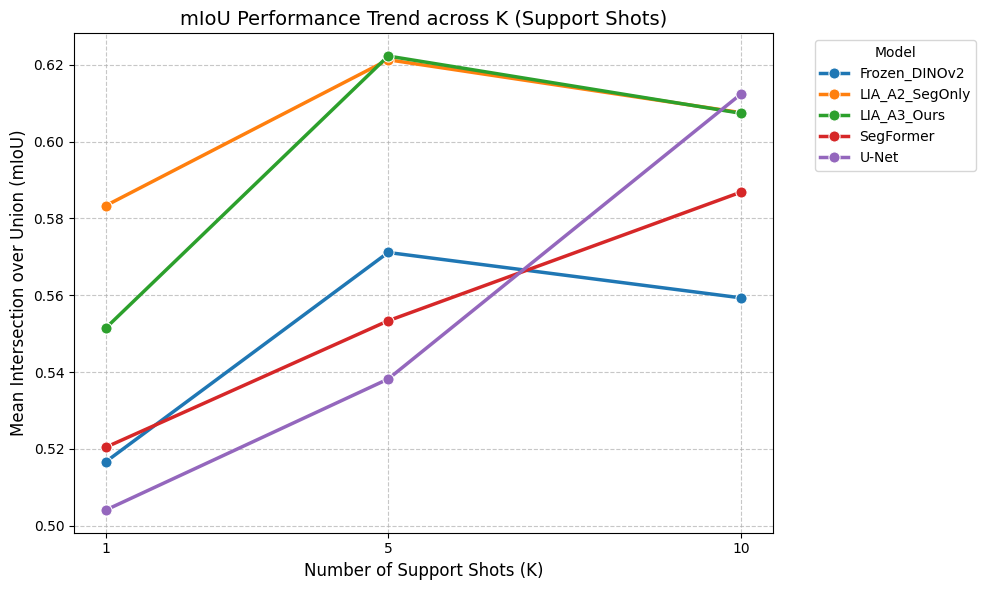

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

# Aggregate the mean mIoU for each model at each K
summary_k = results_df.groupby(['model', 'K'])['mIoU'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.lineplot(data=summary_k, x='K', y='mIoU', hue='model', marker='o', linewidth=2.5, markersize=8)

plt.title('mIoU Performance Trend across K (Support Shots)', fontsize=14)
plt.xlabel('Number of Support Shots (K)', fontsize=12)
plt.ylabel('Mean Intersection over Union (mIoU)', fontsize=12)
plt.xticks(sorted(summary_k['K'].unique()))
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Model', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

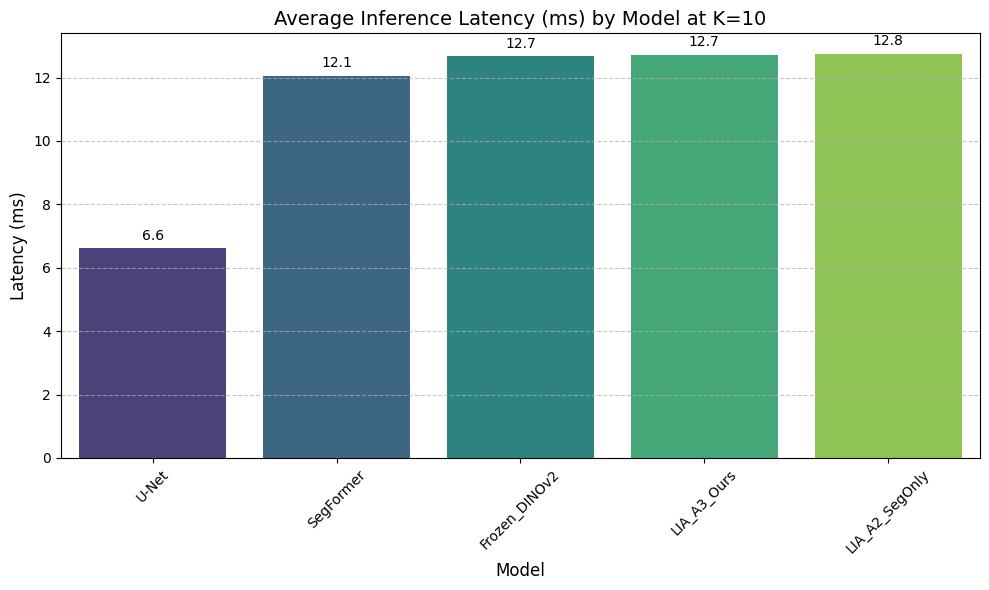

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

# Filter for K=10 and calculate mean latency per model
latency_k10 = results_df[results_df['K'] == 10].groupby('model')['Latency_ms'].mean().reset_index()

# Sort by latency for better visualization
latency_k10 = latency_k10.sort_values('Latency_ms').reset_index(drop=True)

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=latency_k10, x='model', y='Latency_ms', hue='model', palette='viridis', legend=False)

plt.title('Average Inference Latency (ms) by Model at K=10', fontsize=14)
plt.xlabel('Model', fontsize=12)
plt.ylabel('Latency (ms)', fontsize=12)

# Add value labels on top of the bars
for i, p in enumerate(ax.patches):
    ax.annotate(f'{p.get_height():.1f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

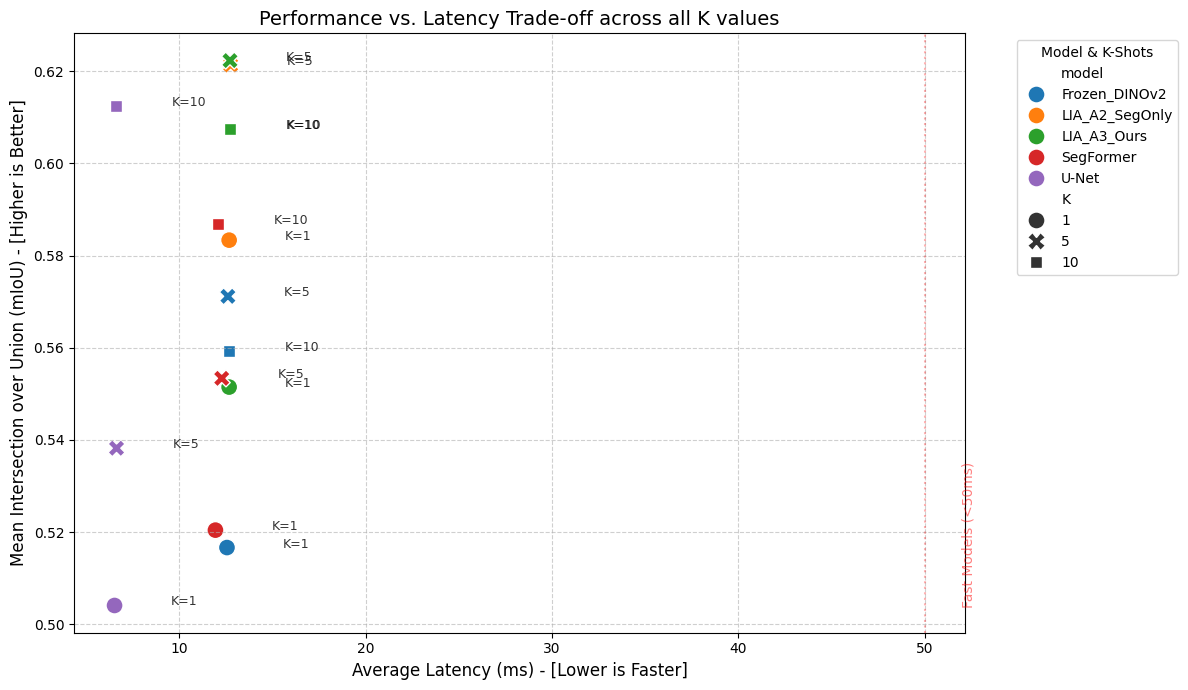

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

# Aggregate mIoU and Latency for each model and K combination
tradeoff_df = results_df.groupby(['model', 'K'])[['mIoU', 'Latency_ms']].mean().reset_index()

plt.figure(figsize=(12, 7))
# Create scatter plot mapping Latency vs mIoU
ax = sns.scatterplot(
    data=tradeoff_df,
    x='Latency_ms',
    y='mIoU',
    hue='model',
    style='K',
    s=150, # Marker size
    palette='tab10'
)

# Add K-value labels next to each point for clarity
for i in range(tradeoff_df.shape[0]):
    plt.text(x=tradeoff_df.Latency_ms[i] + 3,
             y=tradeoff_df.mIoU[i],
             s=f"K={tradeoff_df.K[i]}",
             fontdict=dict(color='black', size=9),
             alpha=0.8)

plt.title('Performance vs. Latency Trade-off across all K values', fontsize=14)
plt.xlabel('Average Latency (ms) - [Lower is Faster]', fontsize=12)
plt.ylabel('Mean Intersection over Union (mIoU) - [Higher is Better]', fontsize=12)

# Best models will be in the top-left quadrant (High mIoU, Low Latency)
plt.axvline(x=50, color='red', linestyle=':', alpha=0.3)
plt.text(52, tradeoff_df['mIoU'].min(), 'Fast Models (<50ms)', color='red', alpha=0.5, rotation=90)

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Model & K-Shots")
plt.tight_layout()
plt.show()

## SECTION N — Qualitative 4-Panel Segmentation Visualization
Generates side-by-side segmentation masks (`Query Image | Ground Truth | Frozen DINOv2 | LIA-FDS Ours`) for both packaging (`bottle`) and food inspection (`cashew`).

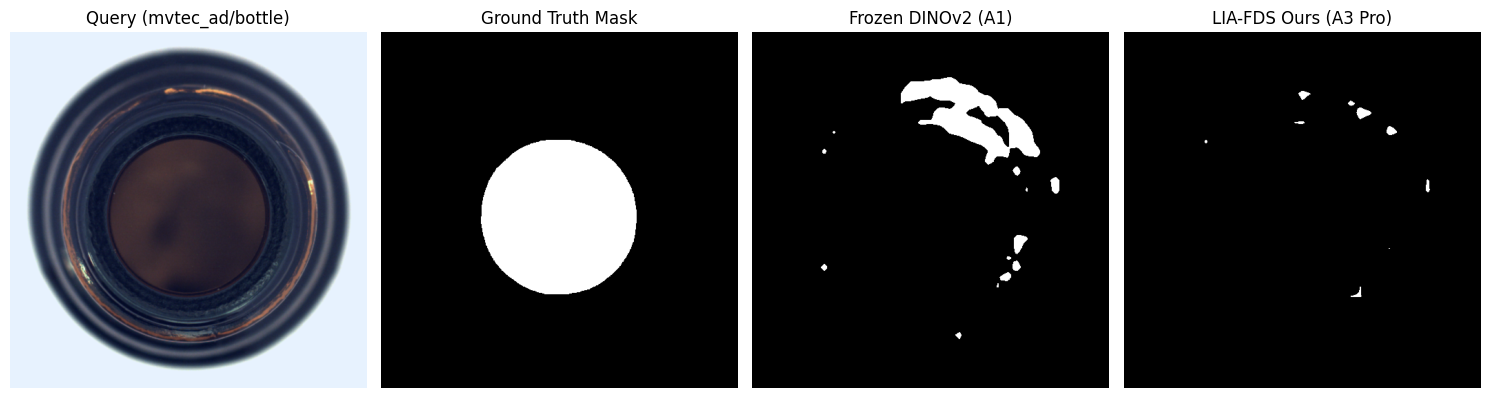

Saved qualitative figure to: /content/drive/MyDrive/LIA_FDS_checkpoints/LIA_FDS_CLEAN_FAST_v5_PRO/paper_outputs/qualitative_mvtec_ad_bottle_K5.png


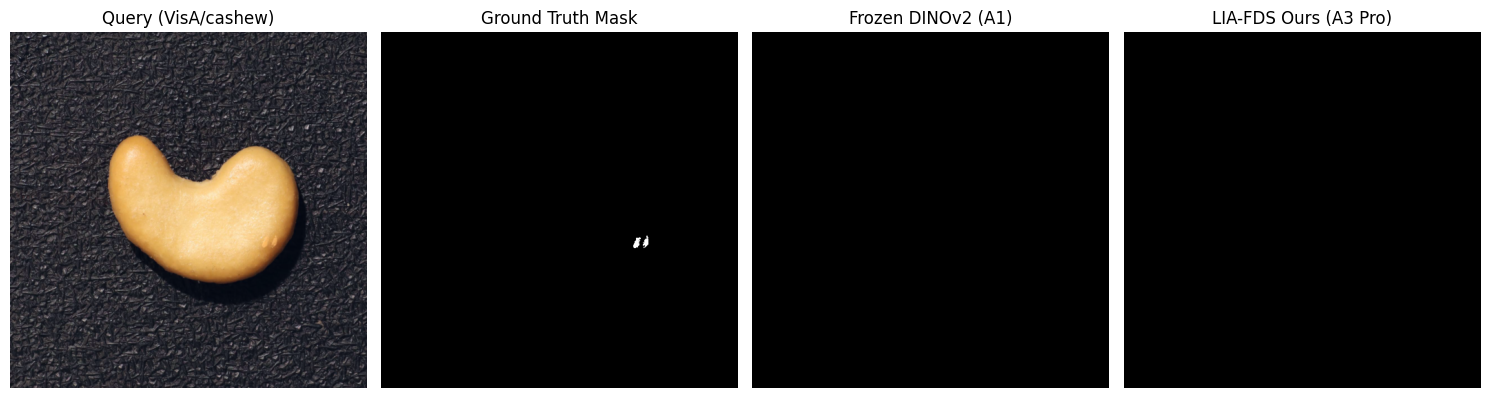

Saved qualitative figure to: /content/drive/MyDrive/LIA_FDS_checkpoints/LIA_FDS_CLEAN_FAST_v5_PRO/paper_outputs/qualitative_VisA_cashew_K5.png


In [23]:
# ==========================================
# SECTION N: 4-Panel Qualitative Visualization
# ==========================================
@torch.no_grad()
def plot_qualitative_comparison(ds_name='mvtec_ad', category='bottle', K=5, seed=42):
    pairs = get_category_pairs(ds_name, category)
    if len(pairs) <= K:
        print(f'Category {ds_name}/{category} not available for visualization.')
        return
    rng = random.Random(seed)
    shuffled = pairs.copy()
    rng.shuffle(shuffled)
    ds_obj = IndustrialFewShotDataset(
        [a for a, _ in shuffled[:K]], [b for _, b in shuffled[:K]],
        [shuffled[K][0]], [shuffled[K][1]], is_train=False
    )
    sample = ds_obj[0]
    s_imgs = sample['support_imgs'].to(DEVICE)
    s_masks = sample['support_masks'].to(DEVICE)
    s_imgs_illum = sample['support_imgs_illum'].to(DEVICE)
    q_img = sample['query_img'].unsqueeze(0).to(DEVICE)
    q_mask = sample['query_mask'].squeeze().cpu().numpy()

    with torch.enable_grad():
        adapt_lia_to_support('A3', ds_name, category, K, seed, s_imgs, s_masks, support_imgs_illum=s_imgs_illum)

    pred_frozen = (frozen_dinov2_baseline(s_imgs, s_masks, q_img).squeeze().cpu().numpy() > 0.5).astype(float)
    fg_p, bg_p = precompute_prototypes(s_imgs, s_masks, use_adapter=True)
    pred_lia = (query_only_predict(q_img, fg_p, bg_p, use_adapter=True).squeeze().cpu().numpy() > 0.5).astype(float)

    rgb = sample['query_img'].permute(1, 2, 0).cpu().numpy()
    rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-8)

    fig, axes = plt.subplots(1, 4, figsize=(15, 4))
    panels = [rgb, q_mask, pred_frozen, pred_lia]
    titles = [f'Query ({ds_name}/{category})', 'Ground Truth Mask', 'Frozen DINOv2 (A1)', 'LIA-FDS Ours (A3 Pro)']
    for ax, im, title in zip(axes, panels, titles):
        ax.imshow(im if im.ndim == 3 else im, cmap=None if im.ndim == 3 else 'gray')
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    save_fig_path = PAPER_DIR / f'qualitative_{ds_name}_{category}_K{K}.png'
    plt.savefig(save_fig_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved qualitative figure to: {save_fig_path}')

if (BASE_DIR / 'mvtec_ad').exists():
    plot_qualitative_comparison(ds_name='mvtec_ad', category='bottle', K=5)
    if (BASE_DIR / 'VisA' / 'cashew').exists():
        plot_qualitative_comparison(ds_name='VisA', category='cashew', K=5)

In [19]:
# ==========================================
# ENSEMBLE SUMMARY & ILLUMINATION STRESS-TEST (SECTION Z.3)
# ==========================================
FINAL_SEEDS = [42, 123, 3407]
ensemble_results_df = run_focused_campaign(seeds_to_run=FINAL_SEEDS)

ensemble_summary = ensemble_results_df.groupby(['model', 'K']).agg(
    mIoU_mean=('mIoU', 'mean'),
    mIoU_std=('mIoU', 'std'),
    Defect_IoU_mean=('Defect_IoU', 'mean'),
    pixel_AUROC_mean=('pixel_AUROC', 'mean'),
    AP_mean=('AP', 'mean'),
    Latency_ms=('Latency_ms', 'mean')
).reset_index().sort_values(['K', 'mIoU_mean'], ascending=[True, False])

print("\n=======================================================")
print("🏆 FINAL ENSEMBLE RESULTS (Averaged across 3 seeds) 🏆")
print("=======================================================")
display(ensemble_summary)

# Per-Category Breakdown at K=5
cat_summary = ensemble_results_df[ensemble_results_df['K'] == 5].groupby(['category', 'model']).agg(
    mIoU=('mIoU', 'mean'),
    Defect_IoU=('Defect_IoU', 'mean'),
    pixel_AUROC=('pixel_AUROC', 'mean')
).reset_index().sort_values(['category', 'mIoU'], ascending=[True, False])

print("\n=======================================================")
print("📊 PER-CATEGORY BREAKDOWN AT K=5 (Averaged across seeds)")
print("=======================================================")
display(cat_summary)

# Illumination Stress-Test Evaluation (Query Images under Harsh Factory Lighting Shifts)
def run_illumination_stress_test(K_eval=5, seed_eval=42):
    stress_rows = []
    for ds_name, category in FOCUSED_TARGETS:
        pairs = get_category_pairs(ds_name, category)
        if len(pairs) <= K_eval:
            continue
        rng = random.Random(seed_eval)
        shuffled = pairs.copy()
        rng.shuffle(shuffled)
        support_pairs = shuffled[:K_eval]
        query_pairs = shuffled[K_eval : K_eval + MAX_QUERY_IMAGES]

        # Note: query_illum=True applies harsh brightness/contrast/gamma/CLAHE shifts to query images!
        ds_stress = IndustrialFewShotDataset(
            [a for a, _ in support_pairs], [b for _, b in support_pairs],
            [a for a, _ in query_pairs], [b for _, b in query_pairs],
            is_train=False, query_illum=True
        )
        first = ds_stress[0]
        s_imgs = first['support_imgs'].to(DEVICE)
        s_masks = first['support_masks'].to(DEVICE)
        s_imgs_illum = first['support_imgs_illum'].to(DEVICE)
        q_imgs_corrupted = [ds_stress[i]['query_img'] for i in range(len(ds_stress))]
        q_masks = [ds_stress[i]['query_mask'] for i in range(len(ds_stress))]

        for model_name in ACTIVE_MODELS:
            if model_name == 'U-Net':
                ckpt = f'{EXPERIMENT_VERSION}__UNet__{ds_name}_{category}__K{K_eval}__seed{seed_eval}'
                m = train_unet_fewshot(ckpt, s_imgs, s_masks)
                pred_fn = lambda q: m(q)
            elif model_name == 'SegFormer':
                ckpt = f'{EXPERIMENT_VERSION}__SegFormer__{ds_name}_{category}__K{K_eval}__seed{seed_eval}'
                m = train_segformer_fewshot(ckpt, s_imgs, s_masks)
                pred_fn = lambda q: torch.sigmoid(F_nn.interpolate(m(pixel_values=q).logits, size=q.shape[-2:], mode='bilinear', align_corners=False))
            elif model_name == 'Frozen_DINOv2':
                fg_p, bg_p = precompute_prototypes(s_imgs, s_masks, use_adapter=False)
                pred_fn = lambda q: query_only_predict(q, fg_p, bg_p, use_adapter=False)
            elif model_name == 'LIA_A2_SegOnly':
                adapt_lia_to_support('A2', ds_name, category, K_eval, seed_eval, s_imgs, s_masks, support_imgs_illum=None)
                fg_p, bg_p = precompute_prototypes(s_imgs, s_masks, use_adapter=True)
                pred_fn = lambda q: query_only_predict(q, fg_p, bg_p, use_adapter=True)
            elif model_name == 'LIA_A3_Ours':
                adapt_lia_to_support('A3', ds_name, category, K_eval, seed_eval, s_imgs, s_masks, support_imgs_illum=s_imgs_illum)
                fg_p, bg_p = precompute_prototypes(s_imgs, s_masks, use_adapter=True)
                pred_fn = lambda q: query_only_predict(q, fg_p, bg_p, use_adapter=True)

            metrics = evaluate_queries_with_latency(pred_fn, q_imgs_corrupted, q_masks)
            stress_rows.append({'model': model_name, 'category': category, **metrics})

    stress_df = pd.DataFrame(stress_rows)
    if not stress_df.empty:
        stress_summary = stress_df.groupby('model')[['mIoU', 'Defect_IoU', 'pixel_AUROC', 'AP']].mean().reset_index().sort_values('mIoU', ascending=False)
        print(f"\n=======================================================")
        print(f"💡 ILLUMINATION STRESS-TEST (Harsh Lighting Shifts @ K={K_eval})")
        print(f"=======================================================")
        display(stress_summary)
    return stress_df

stress_df = run_illumination_stress_test(K_eval=5, seed_eval=42)

[CACHE HIT] U-Net | mvtec_ad/bottle | K=1 | seed=42
[CACHE HIT] SegFormer | mvtec_ad/bottle | K=1 | seed=42
[CACHE HIT] Frozen_DINOv2 | mvtec_ad/bottle | K=1 | seed=42
[CACHE HIT] LIA_A2_SegOnly | mvtec_ad/bottle | K=1 | seed=42
[CACHE HIT] LIA_A3_Ours | mvtec_ad/bottle | K=1 | seed=42
[CACHE HIT] U-Net | mvtec_ad/capsule | K=1 | seed=42
[CACHE HIT] SegFormer | mvtec_ad/capsule | K=1 | seed=42
[CACHE HIT] Frozen_DINOv2 | mvtec_ad/capsule | K=1 | seed=42
[CACHE HIT] LIA_A2_SegOnly | mvtec_ad/capsule | K=1 | seed=42
[CACHE HIT] LIA_A3_Ours | mvtec_ad/capsule | K=1 | seed=42
[CACHE HIT] U-Net | VisA/cashew | K=1 | seed=42
[CACHE HIT] SegFormer | VisA/cashew | K=1 | seed=42
[CACHE HIT] Frozen_DINOv2 | VisA/cashew | K=1 | seed=42
[CACHE HIT] LIA_A2_SegOnly | VisA/cashew | K=1 | seed=42
[CACHE HIT] LIA_A3_Ours | VisA/cashew | K=1 | seed=42
[CACHE HIT] U-Net | VisA/fryum | K=1 | seed=42
[CACHE HIT] SegFormer | VisA/fryum | K=1 | seed=42
[CACHE HIT] Frozen_DINOv2 | VisA/fryum | K=1 | seed=42
[

,model,K,mIoU_mean,mIoU_std,Defect_IoU_mean,pixel_AUROC_mean,AP_mean,Latency_ms
3,LIA_A2_SegOnly,1,0.583348,0.082137,0.200826,0.950275,0.470864,12.674167
6,LIA_A3_Ours,1,0.551472,0.060656,0.140205,0.941361,0.432743,12.672500
9,SegFormer,1,0.520434,0.057666,0.084494,0.839032,0.193307,11.938333
0,Frozen_DINOv2,1,0.516656,0.039978,0.074739,0.955001,0.361140,12.557500
12,U-Net,1,0.504088,0.034581,0.050272,0.565738,0.111963,6.523333
7,LIA_A3_Ours,5,0.622304,0.107727,0.280343,0.973968,0.527870,12.719167
4,LIA_A2_SegOnly,5,0.621335,0.109586,0.276564,0.976502,0.526940,12.755000
1,Frozen_DINOv2,5,0.571150,0.069349,0.200826,0.964694,0.416283,12.606667
10,SegFormer,5,0.553365,0.106563,0.136376,0.900758,0.290477,12.275833
13,U-Net,5,0.538207,0.051342,0.109392,0.649759,0.241042,6.630833



📊 PER-CATEGORY BREAKDOWN AT K=5 (Averaged across seeds)


,category,model,mIoU,Defect_IoU,pixel_AUROC
1,bottle,LIA_A2_SegOnly,0.782003,0.601438,0.972288
2,bottle,LIA_A3_Ours,0.773441,0.587001,0.965803
3,bottle,SegFormer,0.727319,0.496484,0.945301
0,bottle,Frozen_DINOv2,0.652939,0.374060,0.931837
4,bottle,U-Net,0.606898,0.272643,0.715914
7,capsule,LIA_A3_Ours,0.645713,0.303401,0.984237
6,capsule,LIA_A2_SegOnly,0.627937,0.269972,0.982202
5,capsule,Frozen_DINOv2,0.564998,0.174461,0.975983
9,capsule,U-Net,0.512528,0.046147,0.488578
8,capsule,SegFormer,0.502386,0.016412,0.851235


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]


💡 ILLUMINATION STRESS-TEST (Harsh Lighting Shifts @ K=5)


,model,mIoU,Defect_IoU,pixel_AUROC,AP
1,LIA_A2_SegOnly,0.593748,0.234067,0.963820,0.467123
2,LIA_A3_Ours,0.590720,0.224885,0.966572,0.481906
0,Frozen_DINOv2,0.540672,0.162130,0.949793,0.344801
3,SegFormer,0.530552,0.098943,0.884543,0.259245
4,U-Net,0.512763,0.066120,0.624797,0.162048
